# Gap infiltration score (PGI) for any reference gene

A stromal gene such as POSTN surrounds the tumor, but not evenly: at a given distance some directions are poor in it.
The **gap infiltration score** asks which genes are concentrated in these gaps of a **reference gene of your
choice** (`ref_gene`):

1. Stroma only: a grid square is stromal if it has ≤ 1 transcript of CDH1, EPCAM, KRT7, KRT8, TACSTD2.
2. Area-corrected density $D_g = G_g / U$ per polar cell (10 µm rings × 30°; 1 = stromal average).
3. Gaps Γ: in each ring of the band (0–300 µm), the third of the sectors with the lowest reference density.
4. $\mathrm{PGI}_g = \log_2 \frac{\sum_\Gamma G_g / \sum_\Gamma U}{\sum_B G_g / \sum_B U}$ (> 0: denser in the gaps);
   $\rho$ = area-weighted correlation with the reference over the whole band (< 0: mutually exclusive);
   `z_rot` = PGI standardised against the 11 rotations of the gene's map.

## 1. Data and SCOMV

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import stlearn as st
import scomv
from scomv.preparation.skny_calc_distance import calculate_distance

adata = st.ReadXenium(
    feature_cell_matrix_file="../tutorial_data/xenium_data/cell_feature_matrix.h5",
    cell_summary_file="../tutorial_data/xenium_data/cells.csv.gz",
    library_id="example data", image_path=None, scale=1, spot_diameter_fullres=10,
)
sc.pp.filter_genes(adata, min_cells=300)

# 10 µm grid and SKNY tumor boundary (CDH1 / EPCAM)
N_COL = int((adata.obs.imagecol.max() - adata.obs.imagecol.min()) / 10)
N_ROW = int((adata.obs.imagerow.max() - adata.obs.imagerow.min()) / 10)
grid = st.tl.cci.grid(adata, n_row=N_ROW, n_col=N_COL, n_cpus=10, verbose=False)
grid = calculate_distance(grid, pos_marker_ls=["CDH1", "EPCAM"])
sc.pp.filter_cells(adata, min_genes=10)

[calculate_distance] N_ROW=547, N_COL=752, positive cells in grid=100012/411344


In [2]:
from scomv.preparation.choose_roi import add_distance_regions

grid = add_distance_regions(grid)          # distance band of every grid square (used by extract_roi)

# SCOMV for one ROI: polar histogram of every gene, MINAS distance, PCoA
gene_pipe = scomv.SCOMVPipeline(adata=adata, grid=grid, bin_size=10)
gene_out = gene_pipe.run(roi=(2400, 3400, 2400, 3800))
print(f"{len(gene_pipe.selected_genes)} genes in the ROI")

312 genes in the ROI


## 2. POSTN gaps

In [3]:
pgi = scomv.compute_pgi(gene_pipe, ref_gene="POSTN")
pgi.scored.head(15).round(3)

POSTN gaps: 117 of 299 band cells (0-300 µm); the gaps hold 46% of the band's stroma and 26% of its POSTN.  Stromal squares: 1,878 / 3,283 (epithelial markers: CDH1, EPCAM, KRT7, KRT8, TACSTD2)
178 of 311 genes scored (>= 200 transcripts in the stromal band); PGI of POSTN itself: -0.83


,PGI,z_rot,rho_POSTN,density_in_gaps,density_in_band,band_counts,rank
gene,,,,,,,
CCR7,0.546,1.896,-0.435,1.558,1.067,403.0,1
SELL,0.438,1.764,-0.417,1.365,1.008,545.0,2
IL7R,0.417,2.093,-0.556,1.398,1.047,3143.0,3
PRF1,0.397,1.817,-0.305,1.377,1.045,216.0,4
LTB,0.384,1.666,-0.434,1.330,1.019,341.0,5
CD69,0.380,1.552,-0.439,1.357,1.042,832.0,6
DUSP2,0.352,1.245,-0.260,1.320,1.034,206.0,7
CD83,0.335,1.034,-0.290,1.343,1.065,364.0,8
TIGIT,0.317,1.072,-0.393,1.301,1.044,252.0,9


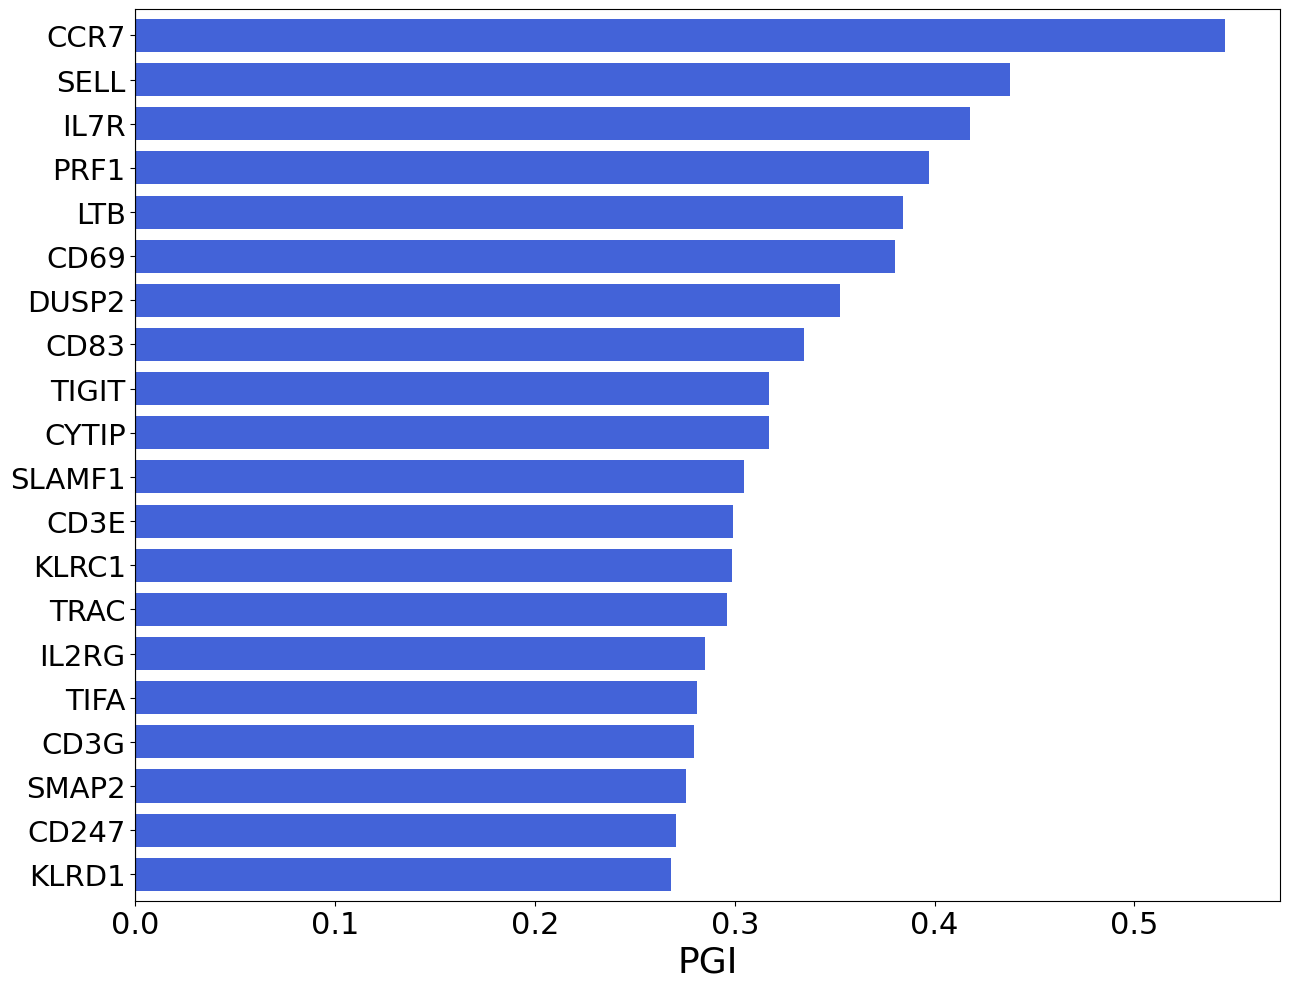

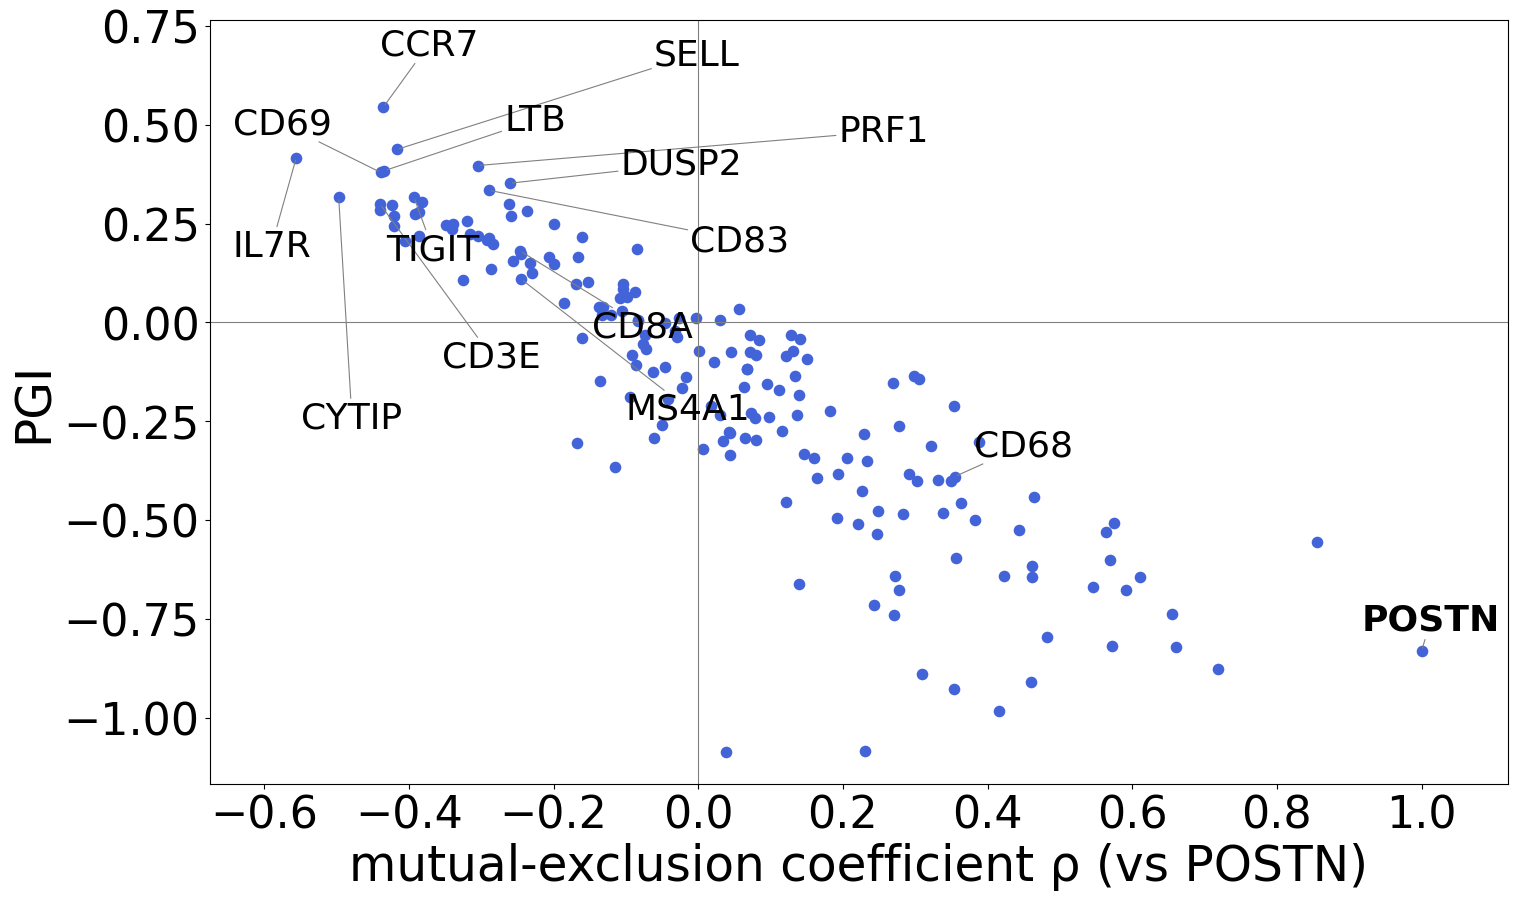

In [4]:
fig_bar, fig_scatter = scomv.plot_pgi_ranking(pgi, top=20, label_genes=["CD3E", "CD8A", "MS4A1", "CD68"])
plt.show()

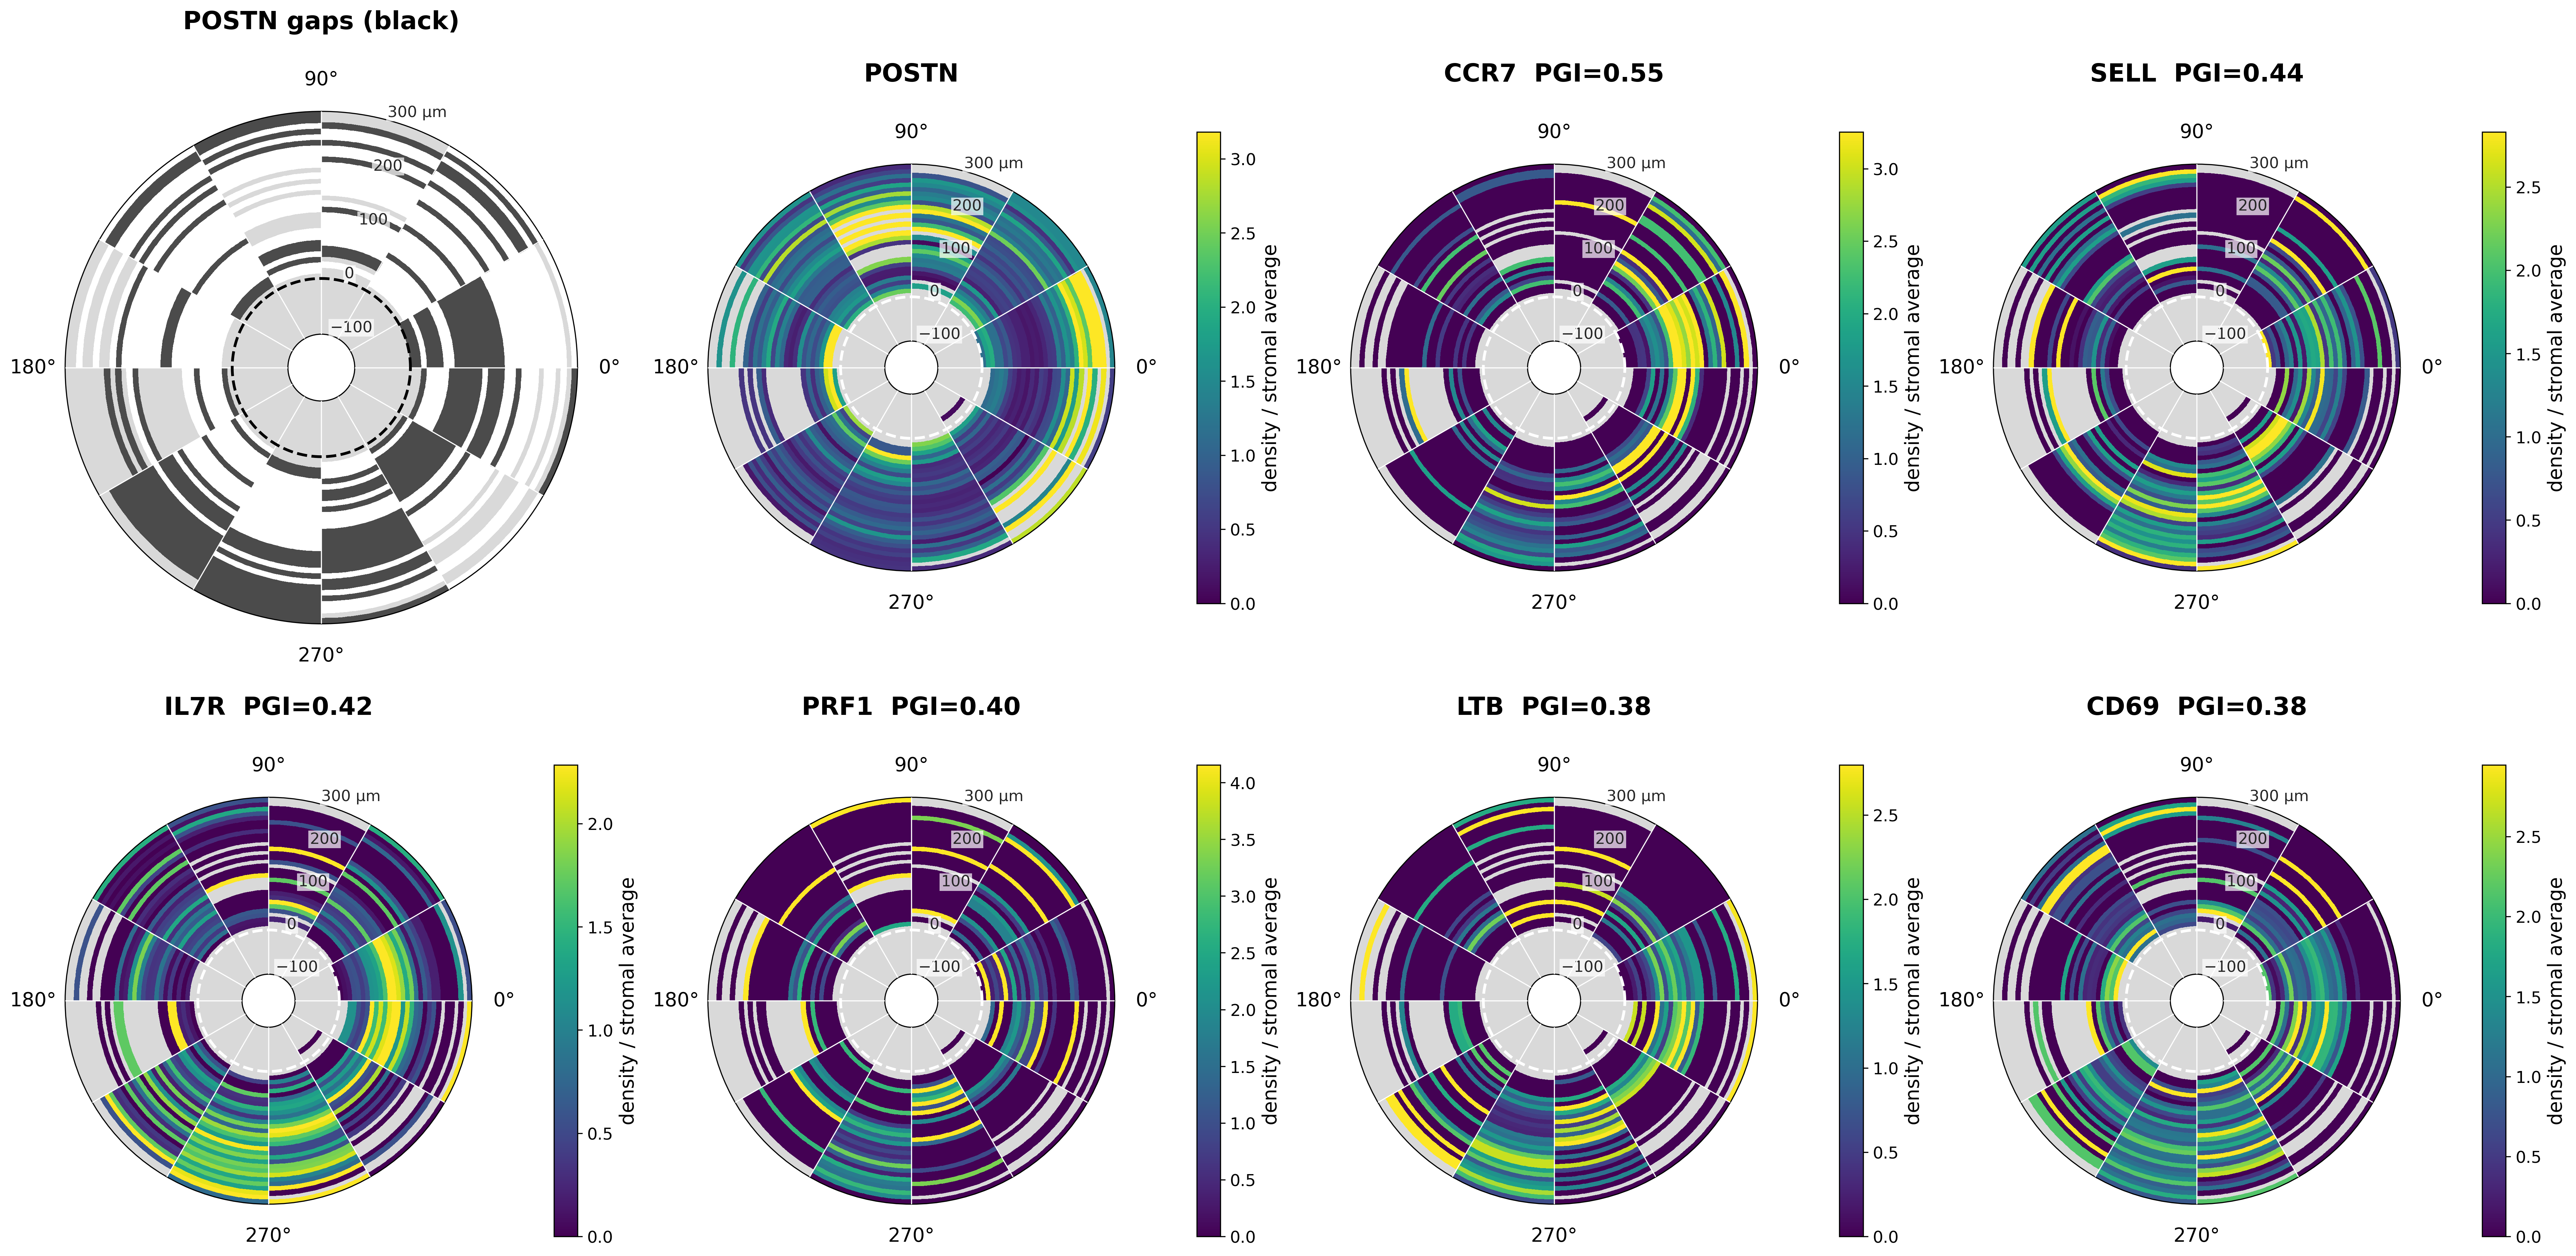

In [5]:
scomv.plot_pgi_polar(pgi, ["POSTN"] + list(pgi.scored.index[:6]))
plt.show()

## 3. Another reference gene

Only `ref_gene` changes. Here the gaps are the LUM-poor (fibroblast-poor) sectors. Colouring by the gene clusters of
the gene_clustering tutorial is possible with `cluster=gene_clusters.labels`.

LUM gaps: 117 of 299 band cells (0-300 µm); the gaps hold 38% of the band's stroma and 24% of its LUM.  Stromal squares: 1,878 / 3,283 (epithelial markers: CDH1, EPCAM, KRT7, KRT8, TACSTD2)
178 of 311 genes scored (>= 200 transcripts in the stromal band); PGI of LUM itself: -0.69


,PGI,z_rot,rho_LUM,density_in_gaps,density_in_band,band_counts,rank
gene,,,,,,,
PRF1,0.479,2.080,-0.231,1.457,1.045,216.0,1
CCR7,0.454,1.402,-0.366,1.462,1.067,403.0,2
SELL,0.443,2.219,-0.367,1.370,1.008,545.0,3
DUSP2,0.391,1.056,-0.195,1.356,1.034,206.0,4
IL7R,0.344,1.806,-0.439,1.329,1.047,3143.0,5
VWF,0.302,1.203,-0.162,1.152,0.934,398.0,6
CD3G,0.302,1.283,-0.244,1.292,1.048,657.0,7
CD69,0.290,1.483,-0.292,1.275,1.042,832.0,8
TIGIT,0.282,0.592,-0.311,1.269,1.044,252.0,9


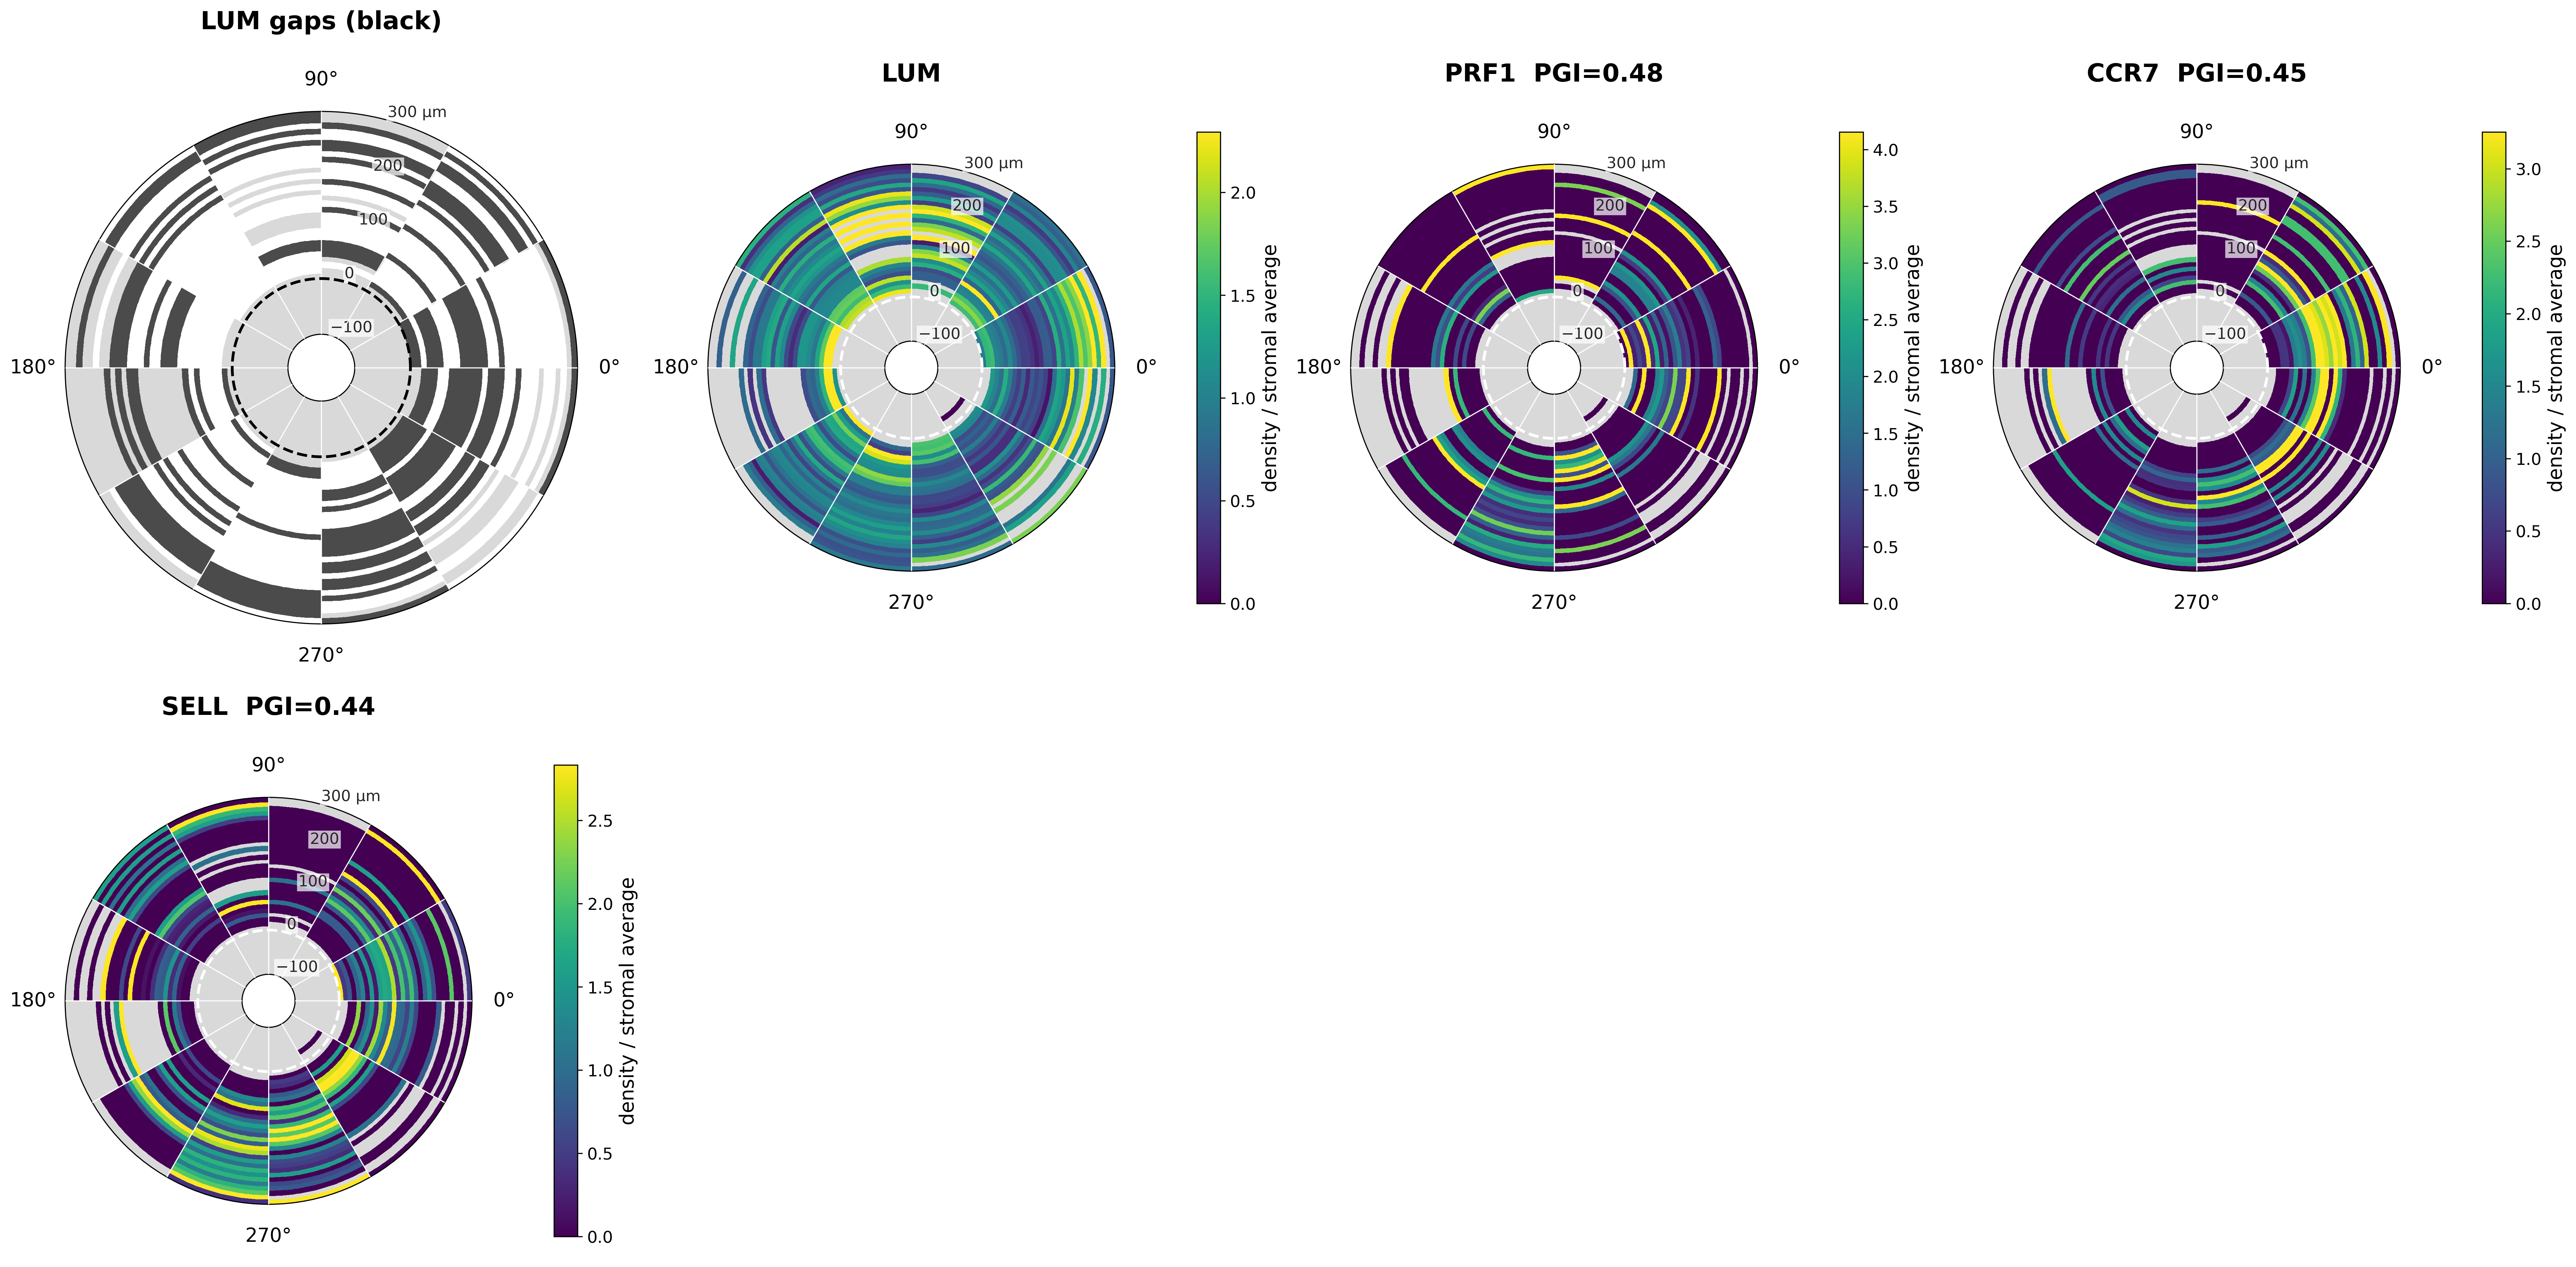

In [6]:
pgi_lum = scomv.compute_pgi(gene_pipe, ref_gene="LUM")
display(pgi_lum.scored.head(10).round(3))
scomv.plot_pgi_polar(pgi_lum, ["LUM"] + list(pgi_lum.scored.index[:3]))
plt.show()

Options: `band_um` (distance range of the band), `gap_frac` (fraction of sectors that are gaps), `epi_genes` /
`epi_max` (stroma definition), `min_band_counts` (genes with fewer transcripts in the band are not ranked).